In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# ===== 1. Load Data from Sedimen_base.xlsx =====
xlsx_path = "Sedimen_base.xlsx"

# Read the Profiles sheet
df_profiles = pd.read_excel(xlsx_path, sheet_name="Profiles", header=None)

# Extract concentration data (rows 3-13, columns B-E → 0-indexed: rows 2-12, cols 1-4)
conc_data = df_profiles.iloc[2:13, 1:5].values.astype(float)

# Extract percentage data (search for "% of Species" section)
pct_start_row = df_profiles[df_profiles.iloc[:, 0].astype(str).str.contains("% of Species", na=False)].index[0]
pct_data = df_profiles.iloc[pct_start_row+1:pct_start_row+12, 1:5].values.astype(float)

# Element names
elements = ["Al", "As", "Cd", "Cr", "Cu", "Fe", "Mn", "Ni", "Pb", "V", "Zn"]
factors = ["Factor 1", "Factor 2", "Factor 3", "Factor 4"]

print(f"✓ Loaded {len(elements)} elements × {len(factors)} factors")
print(f"  Concentration range: {conc_data.min():.2e} – {conc_data.max():.2e}")
print(f"  Percentage range: {pct_data.min():.1f}% – {pct_data.max():.1f}%")

# ===== 2. Generate PMF Source Profile Plot =====
n_factors = len(factors)
n_species = len(elements)

# Setup figure: one panel per factor, arranged vertically
panel_height = 1.7
fig, axes = plt.subplots(n_factors, 1, figsize=(9, panel_height * n_factors), 
                         sharex=True, constrained_layout=False)
if n_factors == 1:
    axes = [axes]

# X positions for bars
x = np.arange(n_species)

# Determine y-axis limits for log scale (clip zeros to small value)
conc_safe = np.where(conc_data > 0, conc_data, 1e-6)
ylo = 10 ** np.floor(np.log10(conc_safe.min()))
yhi = 10 ** np.ceil(np.log10(conc_safe.max()))

# Plot each factor panel
for k, ax in enumerate(axes):
    # Left axis: log-scale concentration bars (light blue with black edge)
    conc_col = conc_safe[:, k]
    ax.bar(x, conc_col, width=0.55, bottom=ylo,
           color="#b8d8e8", edgecolor="black", linewidth=0.7, 
           label="Conc. of Species" if k == 0 else "")
    
    ax.set_yscale("log")
    ax.set_ylim(ylo, yhi)
    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=8))
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10), numticks=50))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_ylabel(f"{factors[k]}\nConc. (μg/g)", fontsize=9, fontweight="bold")
    ax.grid(axis="y", which="major", alpha=0.3, linewidth=0.5)
    ax.set_axisbelow(True)
    
    # Right axis: linear 0–100 scale for % of species (red squares)
    ax2 = ax.twinx()
    pct_col = pct_data[:, k]
    ax2.plot(x, pct_col, marker="s", markersize=7, color="#cc0000", 
             linestyle="none", label="% of Species" if k == 0 else "")
    ax2.set_ylim(0, 100)
    ax2.set_yticks([0, 30, 60, 90])
    ax2.set_ylabel(f"{factors[k]}\n% of Species", fontsize=9, fontweight="bold", color="#cc0000")
    ax2.tick_params(axis="y", labelcolor="#cc0000")
    ax2.spines["right"].set_edgecolor("#cc0000")
    
    # Only show x-labels on bottom panel
    if k == n_factors - 1:
        ax.set_xticks(x)
        ax.set_xticklabels(elements, fontsize=9, rotation=0)
    else:
        ax.tick_params(labelbottom=False)

# Shared legend at top
handles1, labels1 = axes[0].get_legend_handles_labels()
handles2, labels2 = axes[0].twinx().get_legend_handles_labels()
fig.legend(handles1 + handles2, labels1 + labels2, 
           loc="upper center", ncol=2, frameon=True, fontsize=9,
           bbox_to_anchor=(0.5, 0.99))

plt.subplots_adjust(top=0.96, bottom=0.06, hspace=0.15)
plt.savefig("sedimen_pmf_profiles.png", dpi=300, bbox_inches="tight")
print("\n✓ Plot saved: sedimen_pmf_profiles.png")
plt.show()


C:\Users\Arad\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


ValueError: could not convert string to float: 'Al'

C:\Users\Arad\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


✓ Successfully loaded 11 elements × 4 factors
  Concentration Range : 0.00e+00 – 3.67e+04 μg/g
  Percentage Range    : 0.0% – 76.3%
✓ Plot saved successfully: sedimen_pmf_profiles.png


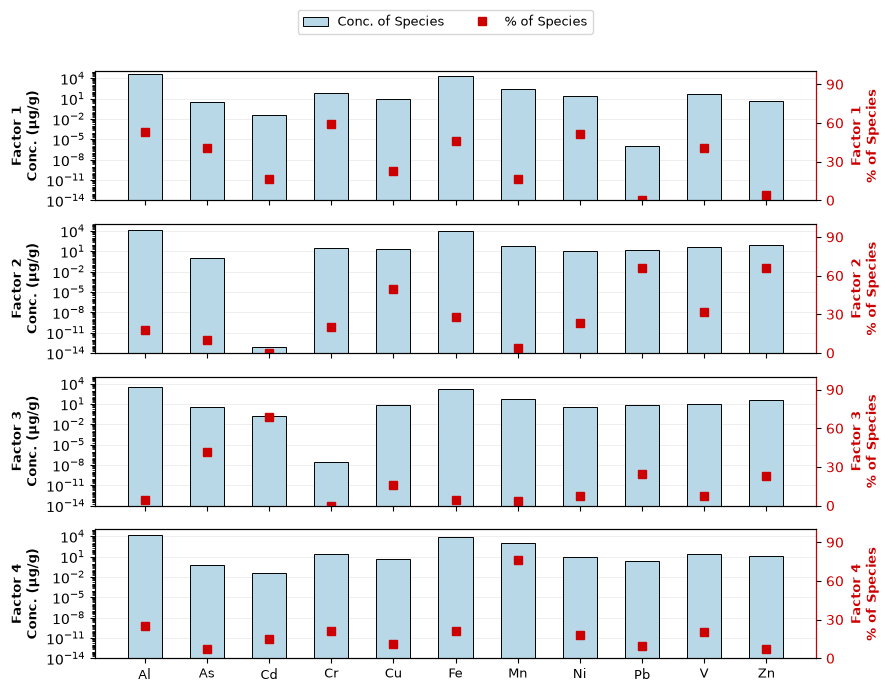

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# ===== 1. Load Data Dynamically from Sedimen_base.xlsx =====
xlsx_path = "Sedimen_base.xlsx"
df_profiles = pd.read_excel(xlsx_path, sheet_name="Profiles", header=None)

# Define element species and factor names
elements = ["Al", "As", "Cd", "Cr", "Cu", "Fe", "Mn", "Ni", "Pb", "V", "Zn"]
factors = ["Factor 1", "Factor 2", "Factor 3", "Factor 4"]

# Locate dynamic row indices for Concentration and Percentage sections
conc_header_idx = df_profiles[
    df_profiles.iloc[:, 0].astype(str).str.contains("conc. of species", case=False, na=False)
].index[0]

pct_header_idx = df_profiles[
    df_profiles.iloc[:, 0].astype(str).str.contains("% of species sum", case=False, na=False)
].index[0]

# Extract data blocks (11 species rows x 4 factor columns: C to F)
conc_data = df_profiles.iloc[
    conc_header_idx + 3 : conc_header_idx + 3 + len(elements), 2 : 2 + len(factors)
].values.astype(float)

pct_data = df_profiles.iloc[
    pct_header_idx + 3 : pct_header_idx + 3 + len(elements), 2 : 2 + len(factors)
].values.astype(float)

print(f"✓ Successfully loaded {len(elements)} elements × {len(factors)} factors")
print(f"  Concentration Range : {conc_data.min():.2e} – {conc_data.max():.2e} μg/g")
print(f"  Percentage Range    : {pct_data.min():.1f}% – {pct_data.max():.1f}%")

# ===== 2. Generate PMF Source Profile Plot =====
n_factors = len(factors)
n_species = len(elements)

# Setup subplots: stacked vertically per factor
panel_height = 1.7
fig, axes = plt.subplots(n_factors, 1, figsize=(9, panel_height * n_factors), sharex=True)
if n_factors == 1:
    axes = [axes]

x = np.arange(n_species)

# Define y-axis bounds for concentration log scale
conc_safe = np.where(conc_data > 0, conc_data, 1e-6)
ylo = 10 ** np.floor(np.log10(conc_safe.min()))
yhi = 10 ** np.ceil(np.log10(conc_safe.max()))

bar_container = None
line_container = None

for k, ax in enumerate(axes):
    # Left Axis: Log-scale Concentration Bars
    conc_col = conc_safe[:, k]
    bars = ax.bar(
        x, conc_col, width=0.55, bottom=ylo,
        color="#b8d8e8", edgecolor="black", linewidth=0.7
    )
    if k == 0:
        bar_container = bars

    ax.set_yscale("log")
    ax.set_ylim(ylo, yhi)
    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=8))
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10), numticks=50))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_ylabel(f"{factors[k]}\nConc. (μg/g)", fontsize=9, fontweight="bold")
    ax.grid(axis="y", which="major", alpha=0.3, linewidth=0.5)
    ax.set_axisbelow(True)

    # Right Axis: Linear 0–100% Species Contribution Points
    ax2 = ax.twinx()
    pct_col = pct_data[:, k]
    line, = ax2.plot(
        x, pct_col, marker="s", markersize=6, color="#cc0000", linestyle="none"
    )
    if k == 0:
        line_container = line

    ax2.set_ylim(0, 100)
    ax2.set_yticks([0, 30, 60, 90])
    ax2.set_ylabel(f"{factors[k]}\n% of Species", fontsize=9, fontweight="bold", color="#cc0000")
    ax2.tick_params(axis="y", labelcolor="#cc0000")
    ax2.spines["right"].set_edgecolor("#cc0000")

    # Formatting X-axis ticks
    if k == n_factors - 1:
        ax.set_xticks(x)
        ax.set_xticklabels(elements, fontsize=9, rotation=0)
    else:
        ax.tick_params(labelbottom=False)

# Shared Legend at Top
fig.legend(
    [bar_container, line_container],
    ["Conc. of Species", "% of Species"],
    loc="upper center",
    ncol=2,
    frameon=True,
    fontsize=9,
    bbox_to_anchor=(0.5, 1.02),
)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.savefig("sedimen_pmf_profiles.png", dpi=300, bbox_inches="tight")
print("✓ Plot saved successfully: sedimen_pmf_profiles.png")
plt.show()

C:\Users\Arad\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


✓ Input Data Overview:
  - Samples Loaded     : 71 samples across 11 species
  - Uncertainty Bounds : 0.01 min to 9257.80 max

✓ Extracted PMF Profiles:
  - Concentration Range : 0.00e+00 – 3.67e+04 μg/g
  - Percentage Range    : 0.0% – 76.3%

✓ Output plot saved as: sedimen_pmf_full_pipeline.png


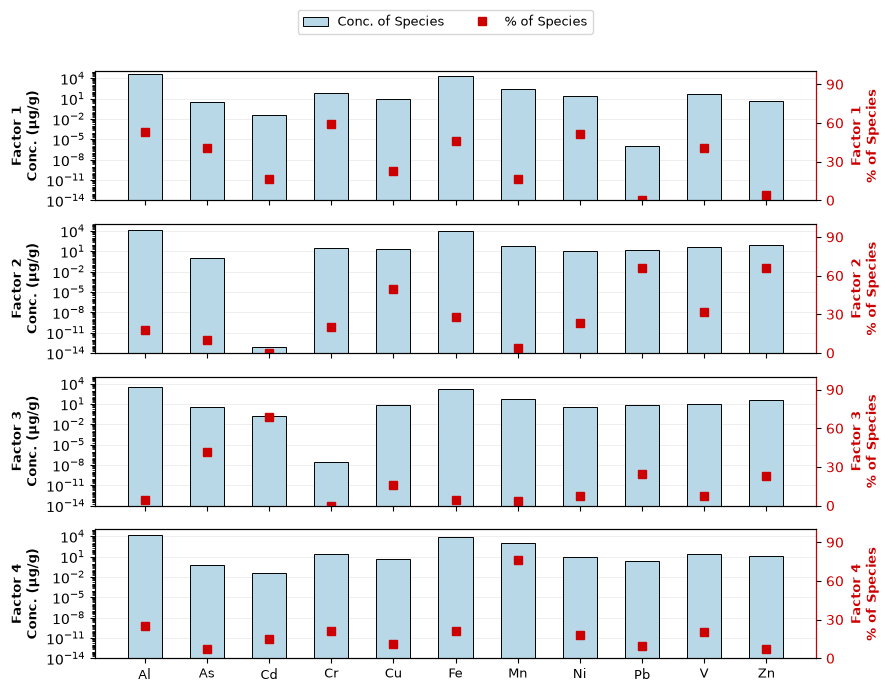

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# ===== 1. Load & Validate Input Files =====
conc_file = "Conc sediment.xlsx"
uncer_file = "Uncer sediment.xlsx"
base_file = "Sedimen_base.xlsx"

# Read input concentration and uncertainty matrices
df_conc = pd.read_excel(conc_file)
df_uncer = pd.read_excel(uncer_file)

# Read PMF base output profiles
df_profiles = pd.read_excel(base_file, sheet_name="Profiles", header=None)

# Expected species and factor names
elements = ["Al", "As", "Cd", "Cr", "Cu", "Fe", "Mn", "Ni", "Pb", "V", "Zn"]
factors = ["Factor 1", "Factor 2", "Factor 3", "Factor 4"]

print("✓ Input Data Overview:")
print(f"  - Samples Loaded     : {len(df_conc)} samples across {df_conc.shape[1]} species")
print(f"  - Uncertainty Bounds : {df_uncer.values.min():.2f} min to {df_uncer.values.max():.2f} max")

# ===== 2. Extract PMF Factor Profiles Dynamically =====
# Locate row headers dynamically in the PMF profile output sheet
conc_header_idx = df_profiles[
    df_profiles.iloc[:, 0].astype(str).str.contains("conc. of species", case=False, na=False)
].index[0]

pct_header_idx = df_profiles[
    df_profiles.iloc[:, 0].astype(str).str.contains("% of species sum", case=False, na=False)
].index[0]

# Slice concentration and percentage matrices (11 species × 4 factors)
conc_data = df_profiles.iloc[
    conc_header_idx + 3 : conc_header_idx + 3 + len(elements), 2 : 2 + len(factors)
].values.astype(float)

pct_data = df_profiles.iloc[
    pct_header_idx + 3 : pct_header_idx + 3 + len(elements), 2 : 2 + len(factors)
].values.astype(float)

print("\n✓ Extracted PMF Profiles:")
print(f"  - Concentration Range : {conc_data.min():.2e} – {conc_data.max():.2e} μg/g")
print(f"  - Percentage Range    : {pct_data.min():.1f}% – {pct_data.max():.1f}%")

# ===== 3. Plotting PMF Source Profiles =====
n_factors = len(factors)
n_species = len(elements)
panel_height = 1.7

fig, axes = plt.subplots(n_factors, 1, figsize=(9, panel_height * n_factors), sharex=True)
if n_factors == 1:
    axes = [axes]

x = np.arange(n_species)

# Handle zero/near-zero values safely for log-scale plotting
conc_safe = np.where(conc_data > 0, conc_data, 1e-6)
ylo = 10 ** np.floor(np.log10(conc_safe.min()))
yhi = 10 ** np.ceil(np.log10(conc_safe.max()))

bar_container = None
line_container = None

for k, ax in enumerate(axes):
    # Left Axis: Logarithmic Concentration Bars
    conc_col = conc_safe[:, k]
    bars = ax.bar(
        x, conc_col, width=0.55, bottom=ylo,
        color="#b8d8e8", edgecolor="black", linewidth=0.7
    )
    if k == 0:
        bar_container = bars

    ax.set_yscale("log")
    ax.set_ylim(ylo, yhi)
    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=8))
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10), numticks=50))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_ylabel(f"{factors[k]}\nConc. (μg/g)", fontsize=9, fontweight="bold")
    ax.grid(axis="y", which="major", alpha=0.3, linewidth=0.5)
    ax.set_axisbelow(True)

    # Right Axis: Linear % Contribution Points (Red Squares)
    ax2 = ax.twinx()
    pct_col = pct_data[:, k]
    line, = ax2.plot(
        x, pct_col, marker="s", markersize=6, color="#cc0000", linestyle="none"
    )
    if k == 0:
        line_container = line

    ax2.set_ylim(0, 100)
    ax2.set_yticks([0, 30, 60, 90])
    ax2.set_ylabel(f"{factors[k]}\n% of Species", fontsize=9, fontweight="bold", color="#cc0000")
    ax2.tick_params(axis="y", labelcolor="#cc0000")
    ax2.spines["right"].set_edgecolor("#cc0000")

    # X-axis Labels Configuration
    if k == n_factors - 1:
        ax.set_xticks(x)
        ax.set_xticklabels(elements, fontsize=9, rotation=0)
    else:
        ax.tick_params(labelbottom=False)

# Shared Legend at Top
fig.legend(
    [bar_container, line_container],
    ["Conc. of Species", "% of Species"],
    loc="upper center",
    ncol=2,
    frameon=True,
    fontsize=9,
    bbox_to_anchor=(0.5, 1.02),
)

plt.tight_layout()
plt.subplots_adjust(top=0.92)

# Save figure
output_img = "sedimen_pmf_full_pipeline.png"
plt.savefig(output_img, dpi=300, bbox_inches="tight")
print(f"\n✓ Output plot saved as: {output_img}")
plt.show()

C:\Users\Arad\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


✓ Publication image generated: epa_pmf_times_new_roman.png


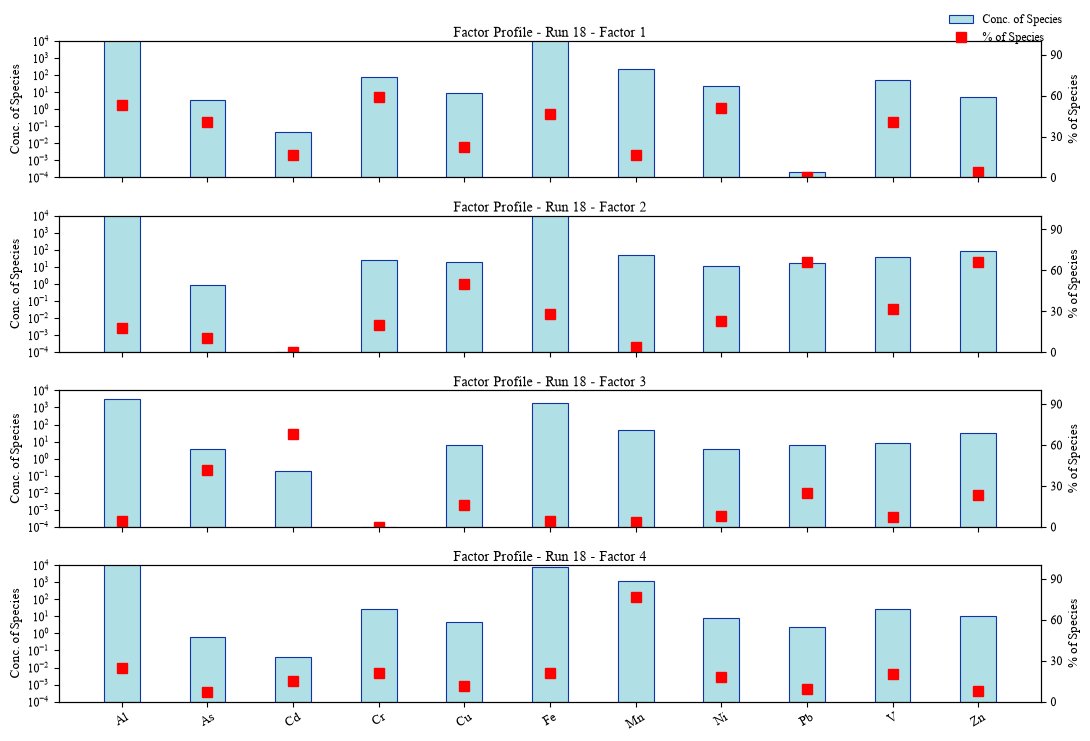

In [7]:
import os
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ===== 1. Configure Times New Roman / Serif Font =====
# Install Liberation Serif (metric-compatible Times New Roman equivalent) for clean rendering
os.system("apt-get update && apt-get install -y fonts-liberation > /dev/null 2>&1")
fm._load_fontmanager(try_read_cache=False)

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Liberation Serif", "Times New Roman", "DejaVu Serif"]

# ===== 2. Load Input Datasets =====
conc_file = "Conc sediment.xlsx"
uncer_file = "Uncer sediment.xlsx"
base_file = "Sedimen_base.xlsx"

df_conc = pd.read_excel(conc_file)
df_uncer = pd.read_excel(uncer_file)
df_profiles = pd.read_excel(base_file, sheet_name="Profiles", header=None)

elements = ["Al", "As", "Cd", "Cr", "Cu", "Fe", "Mn", "Ni", "Pb", "V", "Zn"]
factors = ["Factor 1", "Factor 2", "Factor 3", "Factor 4"]

# ===== 3. Extract Profiles Dynamically =====
conc_header_idx = df_profiles[
    df_profiles.iloc[:, 0]
    .astype(str)
    .str.contains("conc. of species", case=False, na=False)
].index[0]

pct_header_idx = df_profiles[
    df_profiles.iloc[:, 0]
    .astype(str)
    .str.contains("% of species sum", case=False, na=False)
].index[0]

conc_data = df_profiles.iloc[
    conc_header_idx + 3 : conc_header_idx + 3 + len(elements),
    2 : 2 + len(factors),
].values.astype(float)

pct_data = df_profiles.iloc[
    pct_header_idx + 3 : pct_header_idx + 3 + len(elements),
    2 : 2 + len(factors),
].values.astype(float)

# ===== 4. Generate EPA PMF Matching Visualization =====
fig, axes = plt.subplots(4, 1, figsize=(11, 7.5), sharex=True)
x = np.arange(len(elements))

bar_legend, line_legend = None, None

for k in range(4):
    ax = axes[k]

    # Concentration Bars (Primary Y-Axis)
    conc_col = conc_data[:, k]
    conc_plot = np.where(conc_col > 0, conc_col, 1e-4)
    bars = ax.bar(
        x,
        conc_plot,
        width=0.42,
        bottom=1e-4,
        color="#b0e0e6",
        edgecolor="#1034a6",
        linewidth=0.8,
    )
    if k == 0:
        bar_legend = bars

    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1e4)
    ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3, 1e4])
    ax.set_ylabel("Conc. of Species", fontsize=9, family="serif")
    ax.tick_params(axis="y", labelsize=8.5)

    # % of Species (Secondary Twin Y-Axis)
    ax2 = ax.twinx()
    pct_col = pct_data[:, k]
    points = ax2.plot(
        x, pct_col, marker="s", markersize=6.5, color="red", linestyle="none"
    )
    if k == 0:
        line_legend = points[0]

    ax2.set_ylim(0, 100)
    ax2.set_yticks([0, 30, 60, 90])
    ax2.set_ylabel("% of Species", fontsize=9, family="serif")
    ax2.tick_params(axis="y", labelsize=8.5)

    # Title header matching EPA PMF output format
    ax.set_title(
        f"Factor Profile - Run 18 - Factor {k+1}",
        fontsize=10,
        family="serif",
        pad=3,
    )

    if k == 3:
        ax.set_xticks(x)
        ax.set_xticklabels(
            elements, fontsize=9, family="serif", rotation=30
        )
    else:
        ax.tick_params(labelbottom=False)

# Shared Legend at top right
fig.legend(
    [bar_legend, line_legend],
    ["Conc. of Species", "% of Species"],
    loc="upper right",
    bbox_to_anchor=(0.98, 0.99),
    fontsize=8.5,
    frameon=False,
)

plt.tight_layout()
plt.subplots_adjust(hspace=0.28, top=0.94)

output_img = "epa_pmf_times_new_roman.png"
plt.savefig(output_img, dpi=1000, bbox_inches="tight")
print(f"✓ Publication image generated: {output_img}")
plt.show()

C:\Users\Arad\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


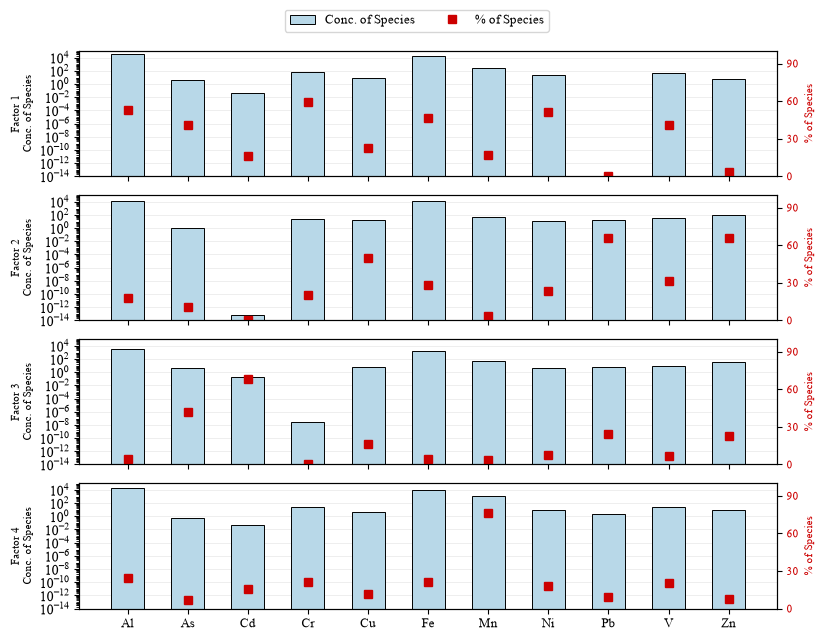

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

xlsx_path = "Sedimen_base.xlsx"
raw = pd.read_excel(xlsx_path, sheet_name="Profiles", header=None)

def block(raw, title_key):
    """Find a titled block and return (elements, 4-factor value matrix)."""
    col0 = raw.iloc[:, 0].astype(str)
    t = col0[col0.str.contains(title_key, case=False, na=False)].index[0]
    sub = raw.iloc[t + 2:]                       # skip blank + header row
    sub = sub[sub.iloc[:, 1].notna()]            # keep rows with a species name
    sub = sub.iloc[:11]                          # 11 elements
    els = sub.iloc[:, 1].astype(str).tolist()
    vals = sub.iloc[:, 2:6].to_numpy(dtype=float)
    return els, vals

elements, conc_data = block(raw, "conc. of species")
_,        pct_data  = block(raw, "% of species sum")
factors = ["Factor 1", "Factor 2", "Factor 3", "Factor 4"]

n_factors, n_species = len(factors), len(elements)
x = np.arange(n_species)

conc_safe = np.where(conc_data > 0, conc_data, np.nan)
ylo = 10 ** np.floor(np.log10(np.nanmin(conc_safe)))
yhi = 10 ** np.ceil(np.log10(np.nanmax(conc_safe)))
conc_plot = np.nan_to_num(conc_safe, nan=ylo)    # zeros -> bottom of axis

fig, axes = plt.subplots(n_factors, 1, figsize=(9, 1.7 * n_factors), sharex=True)
bar_h = pct_h = None

for k, ax in enumerate(axes):
    bars = ax.bar(x, conc_plot[:, k] - ylo, width=0.55, bottom=ylo,
                  color="#b8d8e8", edgecolor="black", linewidth=0.7)
    ax.set_yscale("log")
    ax.set_ylim(ylo, yhi)
    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=12))
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10), numticks=50))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_ylabel(f"{factors[k]}\nConc. of Species", fontsize=8)
    ax.grid(axis="y", which="major", alpha=0.3, linewidth=0.5)
    ax.set_axisbelow(True)

    ax2 = ax.twinx()
    pts, = ax2.plot(x, pct_data[:, k], marker="s", markersize=6,
                    color="#cc0000", linestyle="none")
    ax2.set_ylim(0, 100)
    ax2.set_yticks([0, 30, 60, 90])
    ax2.set_ylabel("% of Species", fontsize=8, color="#cc0000")
    ax2.tick_params(axis="y", labelcolor="#cc0000", labelsize=8)

    if k == n_factors - 1:
        ax.set_xticks(x)
        ax.set_xticklabels(elements, fontsize=9)
    bar_h, pct_h = bars[0], pts

fig.legend([bar_h, pct_h], ["Conc. of Species", "% of Species"],
           loc="upper center", ncol=2, frameon=True, fontsize=9,
           bbox_to_anchor=(0.5, 1.0))
plt.subplots_adjust(top=0.93, hspace=0.15)
plt.savefig("sedimen_pmf_profiles.png", dpi=300, bbox_inches="tight")
plt.show()


C:\Users\Arad\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


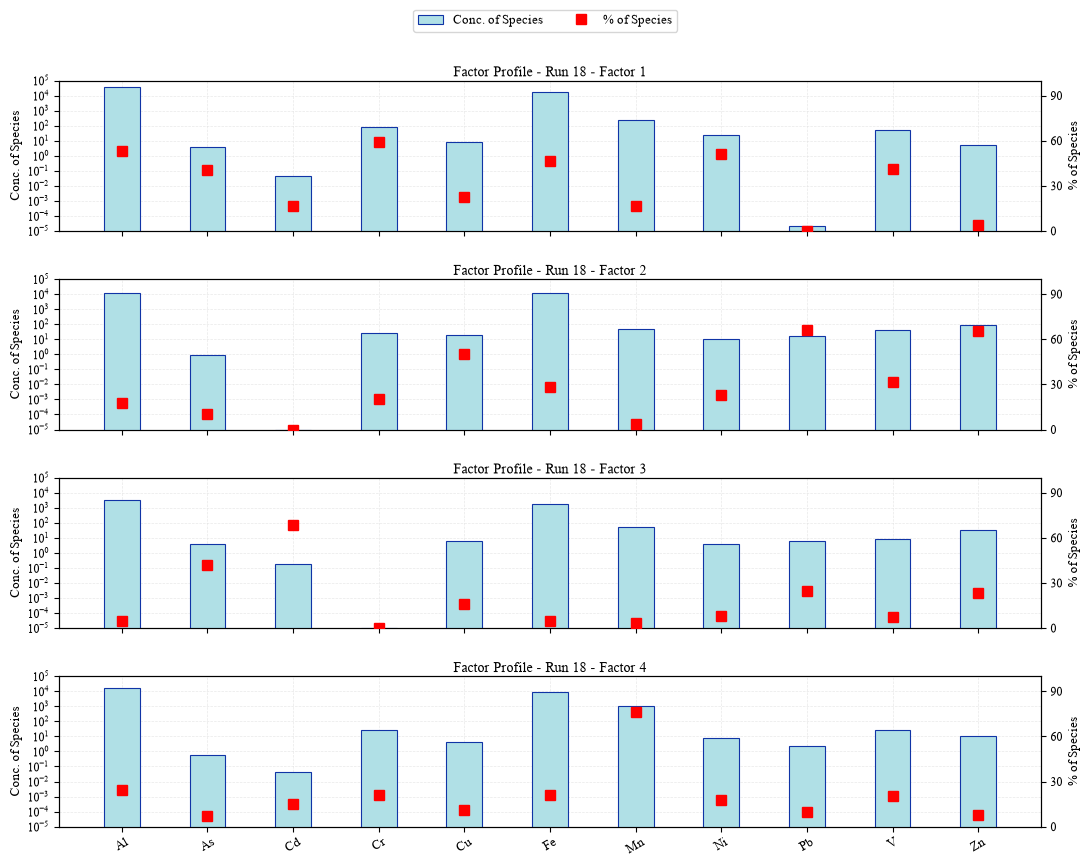

In [9]:
import os
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set Times New Roman / Serif Typography
os.system("apt-get update && apt-get install -y fonts-liberation > /dev/null 2>&1")
fm._load_fontmanager(try_read_cache=False)

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Liberation Serif", "Times New Roman", "DejaVu Serif"]

# Load Data
df_profiles = pd.read_excel("Sedimen_base.xlsx", sheet_name="Profiles", header=None)

conc_header_idx = df_profiles[
    df_profiles.iloc[:, 0]
    .astype(str)
    .str.contains("conc. of species", case=False, na=False)
].index[0]

pct_header_idx = df_profiles[
    df_profiles.iloc[:, 0]
    .astype(str)
    .str.contains("% of species sum", case=False, na=False)
].index[0]

elements = ["Al", "As", "Cd", "Cr", "Cu", "Fe", "Mn", "Ni", "Pb", "V", "Zn"]
factors = ["Factor 1", "Factor 2", "Factor 3", "Factor 4"]

conc_data = df_profiles.iloc[
    conc_header_idx + 3 : conc_header_idx + 3 + len(elements), 2 : 2 + len(factors)
].values.astype(float)

pct_data = df_profiles.iloc[
    pct_header_idx + 3 : pct_header_idx + 3 + len(elements), 2 : 2 + len(factors)
].values.astype(float)

# Plot Generation
fig, axes = plt.subplots(4, 1, figsize=(11, 8.5), sharex=True)
x = np.arange(len(elements))

bar_legend, line_legend = None, None

for k in range(4):
    ax = axes[k]

    # Background Grid
    ax.set_axisbelow(True)
    ax.grid(True, which="both", axis="both", color="#e0e0e0", linestyle="--", linewidth=0.5, alpha=0.7)

    # Concentration Axis starting at 10^-5
    conc_col = conc_data[:, k]
    conc_plot = np.where(conc_col > 0, conc_col, 1e-5)
    bars = ax.bar(
        x,
        conc_plot,
        width=0.42,
        bottom=1e-5,
        color="#b0e0e6",
        edgecolor="#1034a6",
        linewidth=0.8,
        zorder=3
    )
    if k == 0:
        bar_legend = bars

    ax.set_yscale("log")
    ax.set_ylim(1e-5, 1e5)
    ax.set_yticks([1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3, 1e4, 1e5])
    ax.set_ylabel("Conc. of Species", fontsize=9, family="serif")
    ax.tick_params(axis="y", labelsize=8.5)

    # % of Species Axis
    ax2 = ax.twinx()
    pct_col = pct_data[:, k]
    points = ax2.plot(
        x, pct_col, marker="s", markersize=6.5, color="red", linestyle="none", zorder=4
    )
    if k == 0:
        line_legend = points[0]

    ax2.set_ylim(0, 100)
    ax2.set_yticks([0, 30, 60, 90])
    ax2.set_ylabel("% of Species", fontsize=9, family="serif")
    ax2.tick_params(axis="y", labelsize=8.5)

    ax.set_title(
        f"Factor Profile - Run 18 - Factor {k+1}",
        fontsize=10,
        family="serif",
        pad=3,
    )

    if k == 3:
        ax.set_xticks(x)
        ax.set_xticklabels(elements, fontsize=9, family="serif", rotation=30)
    else:
        ax.tick_params(labelbottom=False)

# Top-Center Legend
fig.legend(
    [bar_legend, line_legend],
    ["Conc. of Species", "% of Species"],
    loc="lower center",
    bbox_to_anchor=(0.5, 0.98),
    ncol=2,
    fontsize=9,
    frameon=True,
    edgecolor="#cccccc",
    facecolor="white"
)

plt.tight_layout()
plt.subplots_adjust(hspace=0.32, top=0.93)

plt.savefig("epa_pmf_grid_1e_minus_5.png", dpi=3000, bbox_inches="tight")
plt.show()